In [3]:
import numpy as np
import scipy.stats as ss
import matplotlib.pyplot as plt
n = 100
beta_0 = 5
beta_1 = 2
np.random.seed(1)
x = 10 * ss.uniform.rvs(size=n)
y = beta_0 + beta_1 * x + ss.norm.rvs(loc=0, scale = 1, size = n)
mean_x=np.mean(x)
mean_y=np.mean(y)
print(mean_x)
print(mean_y)

4.8587792760014565
14.80142786070299


In [4]:
import numpy as np
import scipy.stats as ss

# Define the parameters
n = 100
beta_0 = 5
beta_1 = 2
np.random.seed(1)

# Generate x and y data
x = 10 * ss.uniform.rvs(size=n)
y = beta_0 + beta_1 * x + ss.norm.rvs(loc=0, scale=1, size=n)

# Define the functions
def compute_rss(y_estimate, y):
    return sum(np.power(y - y_estimate, 2))

def estimate_y(x, b_0, b_1):
    return b_0 + b_1 * x

# Calculate RSS
rss = compute_rss(estimate_y(x, beta_0, beta_1), y)
print(f"Residual Sum of Squares (RSS): {rss}")


Residual Sum of Squares (RSS): 81.540007425512


In [15]:
import statsmodels.api as sm  # <-- change alias to 'sm'

mod = sm.OLS(y, x)
est = mod.fit()
print(est.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.968
Model:                            OLS   Adj. R-squared (uncentered):              0.967
Method:                 Least Squares   F-statistic:                              2974.
Date:                Sun, 06 Apr 2025   Prob (F-statistic):                    1.14e-75
Time:                        16:51:42   Log-Likelihood:                         -246.89
No. Observations:                 100   AIC:                                      495.8
Df Residuals:                      99   BIC:                                      498.4
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [16]:
import statsmodels.api as stat

mod = stat.OLS(y, x)  # <-- use 'stat' here
est = mod.fit()
print(est.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.968
Model:                            OLS   Adj. R-squared (uncentered):              0.967
Method:                 Least Squares   F-statistic:                              2974.
Date:                Sun, 06 Apr 2025   Prob (F-statistic):                    1.14e-75
Time:                        16:52:07   Log-Likelihood:                         -246.89
No. Observations:                 100   AIC:                                      495.8
Df Residuals:                      99   BIC:                                      498.4
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

Text(0.5, 0, '$y$')

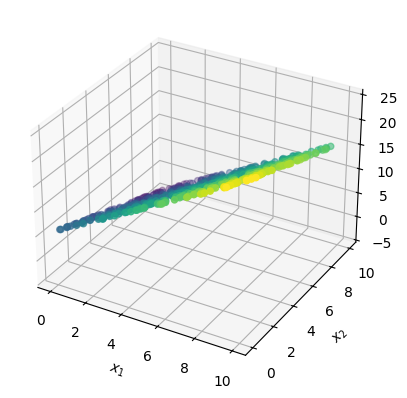

In [17]:
import numpy as np
import scipy.stats as ss

n = 500
beta_0 = 5
beta_1 = 2
beta_2 = -1

np.random.seed(1)

x_1 = 10 * ss.uniform.rvs(size=n)
x_2 = 10 * ss.uniform.rvs(size=n)
#print(x_1)
#print(x_2)
y=beta_0+beta_1*x_1+beta_2*x_2+ss.norm.rvs(loc=0, scale=1)
X=np.stack([x_1,x_2], axis=1)
from mpl_toolkits.mplot3d import Axes3D
fig=plt.figure()
ax=fig.add_subplot(111, projection='3d')
ax.scatter(X[:,0],X[:,1], y,c=y)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$y$")

In [23]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Assuming x_1 and x_2 are already defined and y has been calculated
X = np.column_stack((x_1, x_2))
y = beta_0 + beta_1 * x_1 + beta_2 * x_2 + ss.norm.rvs(0, 1, size=n)

# Create and fit model
lm = LinearRegression(fit_intercept=True)
lm.fit(X, y)

# Coefficients and intercept
print("Intercept:", lm.intercept_)     # Estimate for beta_0
print("Coef for x1:", lm.coef_[0])     # Estimate for beta_1
print("Coef for x2:", lm.coef_[1])     # Estimate for beta_2

# Prediction example
X_0 = np.array([2, 4]).reshape(1, -1)  # Reshaping X_0 correctly as a 2D array
print("Prediction for [2, 4]:", lm.predict(X_0))

# R² score
print("R² score:", lm.score(X, y))

Intercept: 5.124267051698395
Coef for x1: 2.008833695016362
Coef for x2: -1.025872652448133
Prediction for [2, 4]: [5.03844383]
R² score: 0.9742814285778262


In [20]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Assuming x_1 and x_2 are already defined and y has been calculated
X = np.column_stack((x_1, x_2))
y = beta_0 + beta_1 * x_1 + beta_2 * x_2 + ss.norm.rvs(0, 1, size=n)

# Create and fit model
lm = LinearRegression(fit_intercept=True)
lm.fit(X, y)

# Coefficients and intercept
print("Intercept:", lm.intercept_)     # Estimate for beta_0
print("Coef for x1:", lm.coef_[0])     # Estimate for beta_1
print("Coef for x2:", lm.coef_[1])     # Estimate for beta_2

# Prediction example
X_0 = np.array([[2, 4]])               # Reshaped correctly as 2D array
print("Prediction for [2, 4]:", lm.predict(X_0))

# R² score
print("R² score:", lm.score(X, y))


Intercept: 4.9047882252028705
Coef for x1: 2.027952752208743
Coef for x2: -0.9987378746980097
Prediction for [2, 4]: [4.96574223]
R² score: 0.9802824717092428


In [24]:
import scipy.stats as ss
import matplotlib.pyplot as plt

def gen_data(n, h, sd1, sd2):
   x1 = ss.norm.rvs(h, sd1, n)
   y1 = ss.norm.rvs(0, sd1, n)
   x2 = ss.norm.rvs(-h, sd2, n)
   y2 = ss.norm.rvs(0, sd2, n)
   return (x1, y1, x2, y2)

def plot_data(x1, y1, x2, y2):
   plt.figure()
   plt.plot(x1, y1, "o", ms=2)
   plt.plot(x2, y2, "o", ms=2)
   plt.xlabel("$X_1$")
   plt.ylabel("$X_2$")

In [25]:
def prob_to_odds(p):
    if p <= 0 or p >= 1:
        print("Probabilities must be between 0 and 1.")
    return p / (1-p)

NameError: name 'clf' is not defined

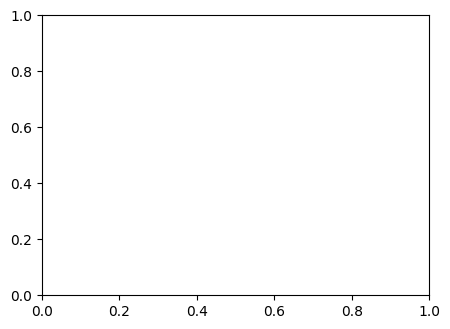

In [27]:
def plot_probs(ax, clf, class_no):
    xx1, xx2 = np.meshgrid(np.arange(-5, 5, 0.1), np.arange(-5, 5, 0.1))
    probs = clf.predict_proba(np.stack((xx1.ravel(), xx2.ravel()), axis=1))
    Z = probs[:,class_no]
    Z = Z.reshape(xx1.shape)
    CS = ax.contourf(xx1, xx2, Z)
    cbar = plt.colorbar(CS)
    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")


plt.figure(figsize=(5,8))
ax = plt.subplot(211)
plot_probs(ax, clf, 0)
plt.title("Pred. prob for class 1")
ax = plt.subplot(212)
plot_probs(ax, clf, 1)
plt.title("Pred. prob for class 2");